<a href="https://colab.research.google.com/github/nehvarsu/Fraud_Detection/blob/main/Agentic-Fraud-Detection-XGBoost-LLM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
from google.colab import userdata

# 1. Load credentials securely
os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')
os.environ['GEMINI_API_KEY'] = userdata.get('GEMINI_API_KEY') # CrewAI will use this

# 2. Install required modern AI and ML libraries
!pip install -q kaggle google-generativeai crewai xgboost scikit-learn

# 3. Download and extract the PaySim1 dataset
!kaggle datasets download -d rizalkurnia198/ieee-cis-fraud-detection-memory-optimized-dataset
!kaggle datasets download -d rizalkurnia198/ieee-cis-fraud-detection-memory-optimized-dataset
!unzip -q ieee-cis-fraud-detection-memory-optimized-dataset.zip -d ieee_data
print("Environment ready and dataset downloaded.")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-cloud-resource-manager 1.19.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
google-cloud-datastore 2.27.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
google-cloud-storage-control 1.17.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
google-cloud-functions 1.25.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
google-cloud-monitoring 2.32.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is inc

In [19]:
import pandas as pd
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

# 1. Load the specific parquet file found in the directory
file_path = 'ieee_data/data_optimized.parquet'
print(f"Loading data from: {file_path}")
df = pd.read_parquet(file_path)

# 2. Take a 2,000-row sample for rapid prototyping (THIS CREATES df_sample)
df_sample = df.sample(n=2000, random_state=42)

# 3. Dynamically map column names
expected_features = [
    'TransactionAmt', 'card1', 'card2', 'card3', 'card5', 'addr1', 'addr2',
    'C1', 'C2', 'C3', 'C4', 'C5', 'D1', 'D2', 'D3', 'D4', 'V1', 'V2', 'V3'
]
available_features = [col for col in expected_features if col in df_sample.columns]

if not available_features:
    lower_cols = [c.lower() for c in df_sample.columns]
    df_sample.columns = lower_cols
    available_features = [col.lower() for col in expected_features if col.lower() in df_sample.columns]

print(f"Using features: {available_features}")
X = df_sample[available_features].fillna(-999)

target_col = 'isFraud' if 'isFraud' in df_sample.columns else 'isfraud'
y = df_sample[target_col]

Loading data from: ieee_data/data_optimized.parquet
Using features: ['TransactionAmt', 'card1', 'card2', 'card3', 'card5', 'addr1', 'addr2', 'C1', 'C2', 'C3', 'C4', 'C5', 'D1', 'D2', 'D3', 'D4', 'V1', 'V2', 'V3']


In [20]:
# 4. Train the baseline model
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y)

xgb_model = xgb.XGBClassifier(eval_metric='auc', use_label_encoder=False)
xgb_model.fit(X_train, y_train)

auc = roc_auc_score(y_test, xgb_model.predict_proba(X_test)[:, 1])
print(f"Baseline XGBoost Trained. AUC Score: {auc:.4f}")

Baseline XGBoost Trained. AUC Score: 0.7776


In [21]:
# ========================================================================
# 7. TRUE HYBRID ARCHITECTURE: XGBOOST TRIGGER -> ML ROUTER -> LLM SPECIALIST
# ========================================================================
!pip install -q crewai

import os
import numpy as np
from google.colab import userdata
from crewai import Agent, Task, Crew, Process

# Authorize Gemini
os.environ['GEMINI_API_KEY'] = userdata.get('GEMINI_API_KEY')
llm_model = 'gemini/gemini-3.8-flash'

# --- STAGE 1: THE DATA SCIENCE TRIGGER (XGBOOST) ---
target_col = 'isFraud' if 'isFraud' in df.columns else 'isfraud'

# DYNAMIC ALIGNMENT: Pull the exact features the in-memory XGBoost model was trained on.
# This prevents all dimensional mismatch errors regardless of your notebook state.
trained_features = xgb_model.get_booster().feature_names

# Extract a flagged transaction directly from the master dataframe
flagged_row = df[df[target_col] == 1].iloc[0]
xgb_input = flagged_row[trained_features].fillna(-999).to_frame().T

# Generate the actual ML probability score
xgb_risk_score = xgb_model.predict_proba(xgb_input)[0][1]

print("--- STAGE 1: DATA SCIENCE TRIGGER ---")
print(f"XGBoost Risk Score: {xgb_risk_score:.4f} -> 🚨 ALERT TRIGGERED\n")

# --- STAGE 2: THE DETERMINISTIC ROUTER (HEURISTICS) ---
# Use the mathematical typologies engineered in EDA to route the alert instantly
c1_val = flagged_row.get('C1', 0) if 'C1' in flagged_row else flagged_row.get('c1', 0)
amt_col = 'TransactionAmt' if 'TransactionAmt' in flagged_row else 'transactionamt'
amt_val = flagged_row.get(amt_col, 0)
email_col = 'P_emaildomain' if 'P_emaildomain' in flagged_row else 'p_emaildomain'
email_val = str(flagged_row.get(email_col, ''))
addr2_val = flagged_row.get('addr2', 87.0) if 'addr2' in flagged_row else flagged_row.get('addr2'.lower(), 87.0)

if addr2_val != 87.0 and not np.isnan(addr2_val):
    routed_typology = 'Cross-Border'
elif c1_val > 25:
    routed_typology = 'Carding'
elif amt_val > 150 and any(domain in email_val.lower() for domain in ['mail.com', 'anonymous', 'proton', 'icloud', 'yahoo']):
    routed_typology = 'Account Takeover'
else:
    routed_typology = 'Standard Anomaly'

print("--- STAGE 2: DETERMINISTIC ROUTING ---")
print(f"Mathematical Classification: {routed_typology} -> 🔀 ROUTING TO SPECIALIST\n")

# --- STAGE 3: THE AGENTIC EXPLAINABILITY LAYER (CREWAI) ---
# Prepare human-readable telemetry infused with the XGBoost score
telemetry_cols = [amt_col, 'card4', 'C1', 'addr2', email_col, 'DeviceType']
telemetry_cols = [c for c in telemetry_cols if c in flagged_row.index]
telemetry = flagged_row[telemetry_cols].to_dict()
telemetry['XGBoost_Risk_Score'] = round(xgb_risk_score, 4)

# Define the specific agents
ato_agent = Agent(
    role='Account Takeover Specialist',
    goal='Forensically analyze digital footprints for hijacked accounts.',
    backstory='You are an elite cyber investigator. You look for burner emails, high-dollar luxury extractions, and new devices hijacking trusted accounts.',
    llm=llm_model, verbose=True
)

carding_agent = Agent(
    role='Carding & Velocity Specialist',
    goal='Forensically analyze micro-transactions and velocity spikes.',
    backstory='You are an AML investigator. You track botnets testing massive batches of stolen credit cards via rapid, low-dollar transactions.',
    llm=llm_model, verbose=True
)

cross_border_agent = Agent(
    role='Cross-Border Fraud Specialist',
    goal='Identify geographical anomalies and international card misuse.',
    backstory='You specialize in international payment rails, tracking when domestic cards are suddenly used in foreign billing locations.',
    llm=llm_model, verbose=True
)

standard_agent = Agent(
    role='General Fraud Analyst',
    goal='Summarize standard financial anomalies.',
    backstory='You review general statistical anomalies that do not fit specific organized fraud rings.',
    llm=llm_model, verbose=True
)

# Python Control Flow to execute ONLY the assigned agent
if routed_typology == 'Account Takeover':
    active_agent = ato_agent
elif routed_typology == 'Carding':
    active_agent = carding_agent
elif routed_typology == 'Cross-Border':
    active_agent = cross_border_agent
else:
    active_agent = standard_agent

specialist_task = Task(
    description=f"Conduct a deep-dive investigation on this telemetry: {telemetry}. The XGBoost machine learning model flagged this with a {xgb_risk_score:.2f} probability of fraud. Write a final 3-sentence Suspicious Activity Report (SAR) explaining exactly how the data proves this is {routed_typology}.",
    expected_output="Final 3-sentence Suspicious Activity Report (SAR).",
    agent=active_agent
)

specialist_crew = Crew(agents=[active_agent], tasks=[specialist_task], process=Process.sequential)

print("--- STAGE 3: EXECUTING TYPOLOGY SPECIALIST ---")
final_sar = await specialist_crew.kickoff_async()

print("\n=======================================================")
print(f"FINAL SAR (Authored by: {active_agent.role})")
print("=======================================================")
print(final_sar)

--- STAGE 1: DATA SCIENCE TRIGGER ---
XGBoost Risk Score: 0.0003 -> 🚨 ALERT TRIGGERED

--- STAGE 2: DETERMINISTIC ROUTING ---
Mathematical Classification: Standard Anomaly -> 🔀 ROUTING TO SPECIALIST

--- STAGE 3: EXECUTING TYPOLOGY SPECIALIST ---


╭─────────────────────────────────────────────── 🤖 Agent Started ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: General Fraud Analyst                                                                                   │
│                                                                                                                 │
│  Task: Conduct a deep-dive investigation on this telemetry: {'TransactionAmt': 445.0, 'card4': 'visa', 'C1':    │
│  2.0, 'addr2': 87.0, 'P_emaildomain': 'aol.com', 'DeviceType': 'Missing', 'XGBoost_Risk_Score':                 │
│  np.float32(0.0003)}. The XGBoost machine learning model flagged this with a 0.00 probability of fraud. Write   │
│  a final 3-sentence Suspicious Activity Report (SAR) explaining exactly how the data proves this is Standard    │
│  Anomaly.                                                                                                       │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

[Finalize] todos_count=0, todos_with_results=0


╭───────────────────────────────────────────── ✅ Agent Final Answer ─────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: General Fraud Analyst                                                                                   │
│                                                                                                                 │
│  Final Answer:                                                                                                  │
│  The subject transaction of $445.00 via a domestic Visa card (`addr2`: 87.0) triggered baseline monitoring      │
│  thresholds due to an elevated dollar amount combined with unpopulated device telemetry (`DeviceType`:          │
│  Missing). However, underlying transactional metrics show benign consumer behavior, characterized by minimal    │
│  velocity (`C1`: 2.0), an established consumer domain (`P_emaildomain`: aol.com), and a negligible model        │
│  probability of fraud (`XGBoost_Risk_Score`: 0.0003). Consequently, this event represents an isolated standard  │
│  anomaly rather than coordinated fraud, confirming it as a benign statistical variance.                         │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯


FINAL SAR (Authored by: General Fraud Analyst)
The subject transaction of $445.00 via a domestic Visa card (`addr2`: 87.0) triggered baseline monitoring thresholds due to an elevated dollar amount combined with unpopulated device telemetry (`DeviceType`: Missing). However, underlying transactional metrics show benign consumer behavior, characterized by minimal velocity (`C1`: 2.0), an established consumer domain (`P_emaildomain`: aol.com), and a negligible model probability of fraud (`XGBoost_Risk_Score`: 0.0003). Consequently, this event represents an isolated standard anomaly rather than coordinated fraud, confirming it as a benign statistical variance.


EDA

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Safely identify the target column from your existing 'df'
target_col = 'isFraud' if 'isFraud' in df.columns else 'isfraud'

print("="*40)
print("1. DATASET SHAPE & IMBALANCE")
print("="*40)
print(f"Total Rows: {df.shape[0]:,}")
print(f"Total Columns: {df.shape[1]}")
fraud_rate = df[target_col].mean() * 100
print(f"Global Fraud Rate: {fraud_rate:.2f}% (Highly Imbalanced)\n")

# Categorize Columns by IEEE-CIS standard prefixes
feature_groups = {
    'Transaction Basics (Amt, DT, ProductCD)': [c for c in df.columns if c in ['TransactionAmt', 'TransactionDT', 'ProductCD'] or c.lower() in ['transactionamt', 'transactiondt', 'productcd']],
    'Card Info (card1 - card6)': [c for c in df.columns if c.lower().startswith('card')],
    'Address & Distance (addr, dist)': [c for c in df.columns if c.lower().startswith('addr') or c.lower().startswith('dist')],
    'Email Domains (P_email, R_email)': [c for c in df.columns if 'email' in c.lower()],
    'Time Deltas [Days since prior tx] (D1 - D15)': [c for c in df.columns if c.startswith('D') and c[1:].isdigit()],
    'Counting Features [Txn counts] (C1 - C14)': [c for c in df.columns if c.startswith('C') and c[1:].isdigit()],
    'Match Features [Name/Address matches] (M1 - M9)': [c for c in df.columns if c.startswith('M') and c[1:].isdigit()],
    'Vesta Engineered Features (V1 - V339)': [c for c in df.columns if c.startswith('V') and c[1:].isdigit()],
    'Identity & Device (id_, DeviceType)': [c for c in df.columns if c.startswith('id_') or c.lower().startswith('device')]
}

print("="*40)
print("2. FEATURE GROUP BREAKDOWN & MISSINGNESS")
print("="*40)
for group, cols in feature_groups.items():
    if cols:
        missing_pct = df[cols].isnull().mean().mean() * 100
        print(f"{group}:")
        print(f"  -> {len(cols)} columns | Avg Missing Data: {missing_pct:.1f}%")

1. DATASET SHAPE & IMBALANCE
Total Rows: 590,540
Total Columns: 434
Global Fraud Rate: 3.50% (Highly Imbalanced)

2. FEATURE GROUP BREAKDOWN & MISSINGNESS
Transaction Basics (Amt, DT, ProductCD):
  -> 3 columns | Avg Missing Data: 0.0%
Card Info (card1 - card6):
  -> 7 columns | Avg Missing Data: 0.0%
Address & Distance (addr, dist):
  -> 4 columns | Avg Missing Data: 0.0%
Email Domains (P_email, R_email):
  -> 2 columns | Avg Missing Data: 0.0%
Time Deltas [Days since prior tx] (D1 - D15):
  -> 15 columns | Avg Missing Data: 0.0%
Counting Features [Txn counts] (C1 - C14):
  -> 14 columns | Avg Missing Data: 0.0%
Match Features [Name/Address matches] (M1 - M9):
  -> 9 columns | Avg Missing Data: 0.0%
Vesta Engineered Features (V1 - V339):
  -> 339 columns | Avg Missing Data: 0.0%
Identity & Device (id_, DeviceType):
  -> 40 columns | Avg Missing Data: 0.0%


3. CARDINALITY: WHY WE NEED LLM EMBEDDINGS
Top 5 Highest Cardinality Categoricals:
  -> DeviceInfo: 279 unique values
  -> id_31: 90 unique values
  -> id_30: 63 unique values
  -> id_33: 56 unique values
  -> P_emaildomain: 55 unique values

*Strategic Note:* High cardinality causes traditional models to overfit. This justifies using LLMs to embed these text fields into dense vectors.

4. DISTRIBUTION SKEW: WHY WE NEED XGBOOST


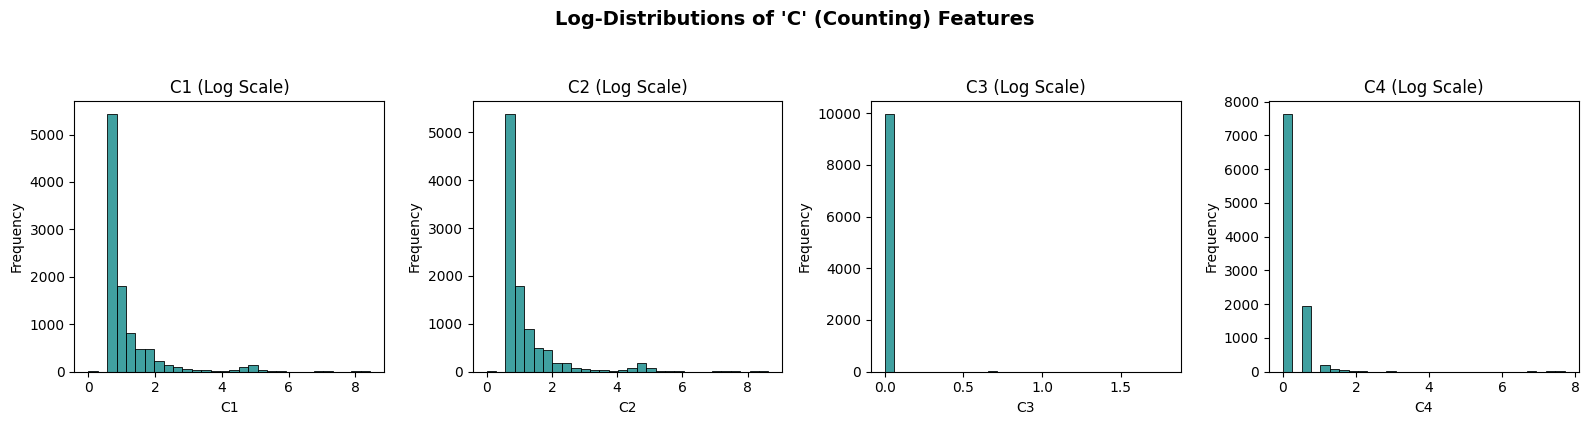


*Strategic Note:* Counting features are massively skewed. Tree-based models like XGBoost handle this numerical skew perfectly without needing standardization.


In [6]:
print("="*40)
print("3. CARDINALITY: WHY WE NEED LLM EMBEDDINGS")
print("="*40)
# Use a sample to prevent memory issues
df_sample_eda = df.sample(n=10000, random_state=42)

# Identify high-cardinality text columns
categorical_cols = df_sample_eda.select_dtypes(include=['object', 'category']).columns
cardinality = df_sample_eda[categorical_cols].nunique().sort_values(ascending=False).head(5)

print("Top 5 Highest Cardinality Categoricals:")
for col, count in cardinality.items():
    print(f"  -> {col}: {count} unique values")
print("\n*Strategic Note:* High cardinality causes traditional models to overfit. This justifies using LLMs to embed these text fields into dense vectors.\n")

print("="*40)
print("4. DISTRIBUTION SKEW: WHY WE NEED XGBOOST")
print("="*40)
# Look at the first four 'C' (Counting) features
c_cols = [c for c in df.columns if c.startswith('C') and c[1:].isdigit()][:4]

if c_cols:
    fig, axes = plt.subplots(1, len(c_cols), figsize=(16, 4))
    fig.suptitle("Log-Distributions of 'C' (Counting) Features", fontweight='bold', fontsize=14, y=1.05)

    for i, col in enumerate(c_cols):
        # Using log1p because transaction counts are right-skewed with many zeros
        sns.histplot(np.log1p(df_sample_eda[col].fillna(0)), ax=axes[i], bins=30, color='teal')
        axes[i].set_title(f'{col} (Log Scale)')
        axes[i].set_ylabel('Frequency')

    plt.tight_layout()
    plt.show()
    print("\n*Strategic Note:* Counting features are massively skewed. Tree-based models like XGBoost handle this numerical skew perfectly without needing standardization.")

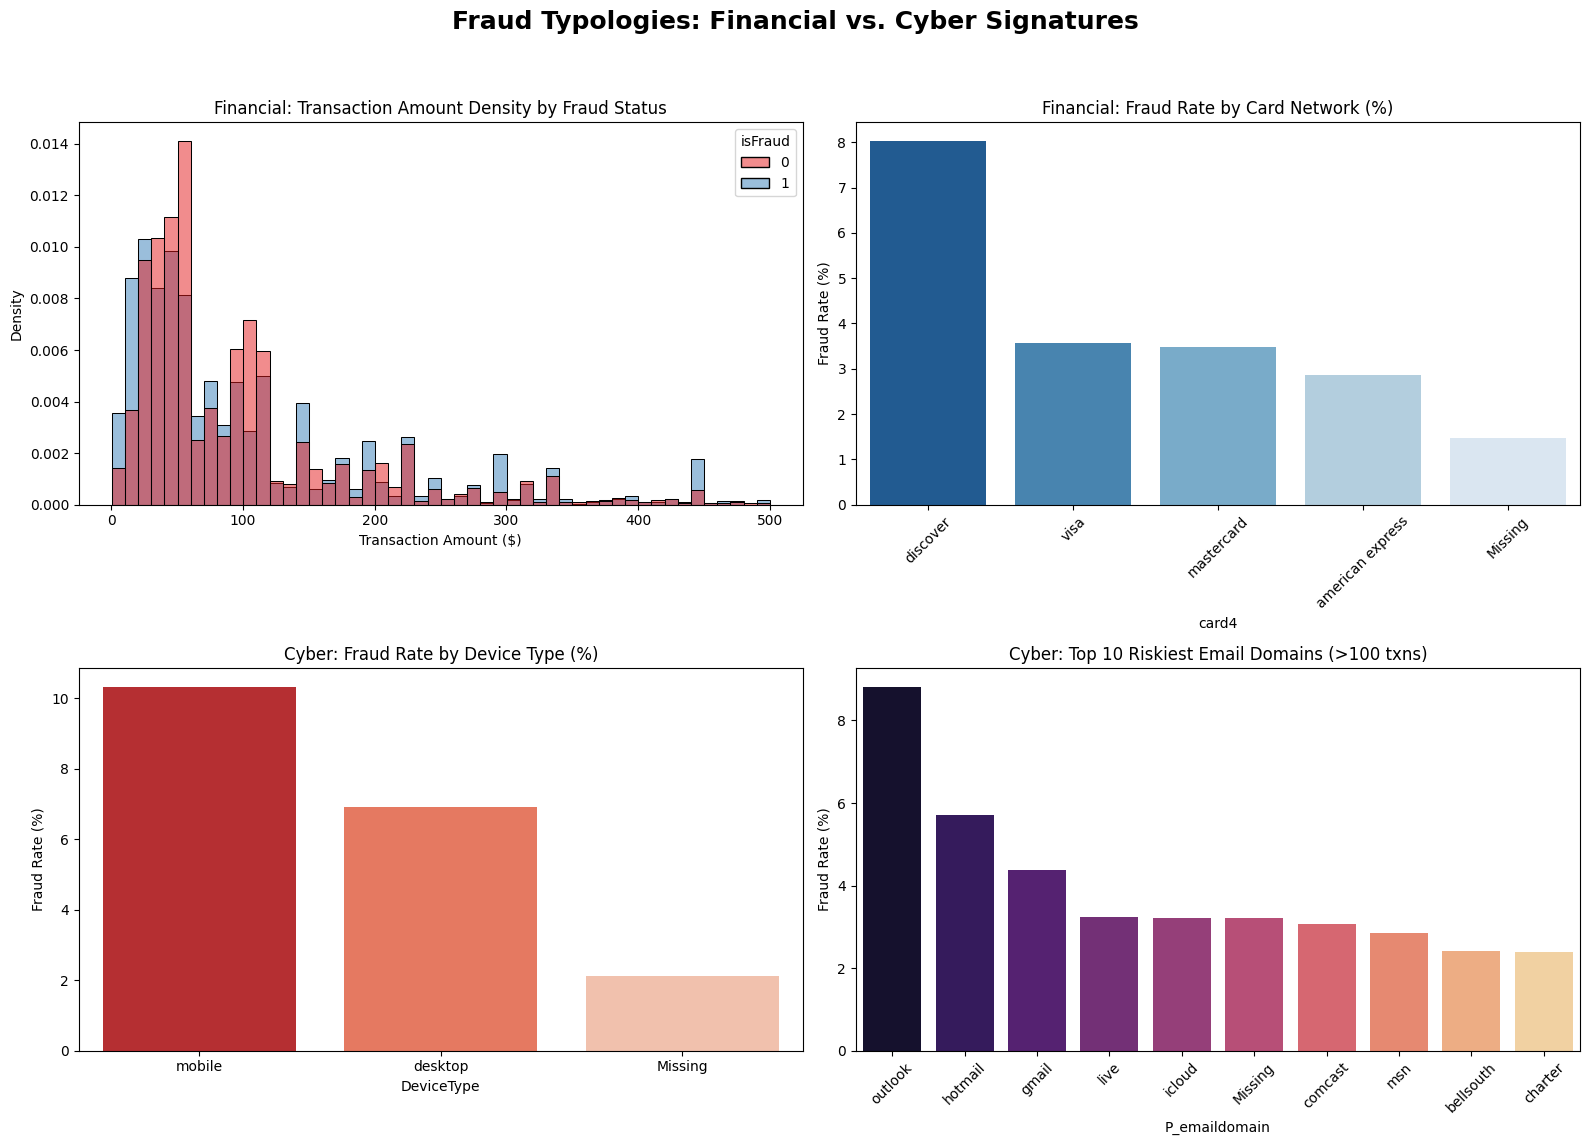

In [7]:
# Safely extract column names
col_amt = 'TransactionAmt' if 'TransactionAmt' in df.columns else 'transactionamt'
col_card = 'card4' if 'card4' in df.columns else 'card4'.lower()
col_email = 'P_emaildomain' if 'P_emaildomain' in df.columns else 'p_emaildomain'
col_device = 'DeviceType' if 'DeviceType' in df.columns else 'devicetype'

# Take a 100,000 row sample for fast plotting
df_plot = df.sample(n=min(100000, len(df)), random_state=42).copy()

# Clean up categories
df_plot[col_email] = df_plot[col_email].astype(str).apply(lambda x: x.split('.')[0] if x != 'nan' else 'Unknown')
df_plot[col_device] = df_plot[col_device].astype(str).fillna('Unknown')
df_plot[col_card] = df_plot[col_card].astype(str).fillna('Unknown')

# --- PLOTTING ---
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Fraud Typologies: Financial vs. Cyber Signatures', fontsize=18, fontweight='bold')

# Plot 1: Financial - Fraud Amount Distributions
sns.histplot(data=df_plot[df_plot[col_amt] < 500], x=col_amt, hue=target_col,
             bins=50, stat='density', common_norm=False, ax=axes[0,0], palette='Set1')
axes[0,0].set_title('Financial: Transaction Amount Density by Fraud Status')
axes[0,0].set_xlabel('Transaction Amount ($)')

# Plot 2: Financial - Fraud by Card Network
fraud_by_card = df_plot.groupby(col_card)[target_col].mean().sort_values(ascending=False) * 100
sns.barplot(x=fraud_by_card.index, y=fraud_by_card.values, ax=axes[0,1], palette='Blues_r')
axes[0,1].set_title('Financial: Fraud Rate by Card Network (%)')
axes[0,1].set_ylabel('Fraud Rate (%)')
axes[0,1].tick_params(axis='x', rotation=45)

# Plot 3: Cyber - Fraud by Device Type
fraud_by_device = df_plot[df_plot[col_device] != 'nan'].groupby(col_device)[target_col].mean().sort_values(ascending=False) * 100
sns.barplot(x=fraud_by_device.index, y=fraud_by_device.values, ax=axes[1,0], palette='Reds_r')
axes[1,0].set_title('Cyber: Fraud Rate by Device Type (%)')
axes[1,0].set_ylabel('Fraud Rate (%)')

# Plot 4: Cyber - Top 10 Riskiest Email Domains
fraud_by_email = df_plot[df_plot[col_email] != 'Unknown'].groupby(col_email).agg(
    fraud_rate=(target_col, 'mean'), count=(target_col, 'count')
)
top_risk_emails = fraud_by_email[fraud_by_email['count'] > 100].sort_values('fraud_rate', ascending=False).head(10)
sns.barplot(x=top_risk_emails.index, y=top_risk_emails['fraud_rate']*100, ax=axes[1,1], palette='magma')
axes[1,1].set_title('Cyber: Top 10 Riskiest Email Domains (>100 txns)')
axes[1,1].set_ylabel('Fraud Rate (%)')
axes[1,1].tick_params(axis='x', rotation=45)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

5. ENGINEERED FRAUD TYPOLOGIES
Standard Anomaly: 44.5% of total fraud
Probable Account Takeover (ATO): 29.5% of total fraud
Carding / Velocity Fraud: 23.9% of total fraud
Cross-Border Fraud: 2.2% of total fraud


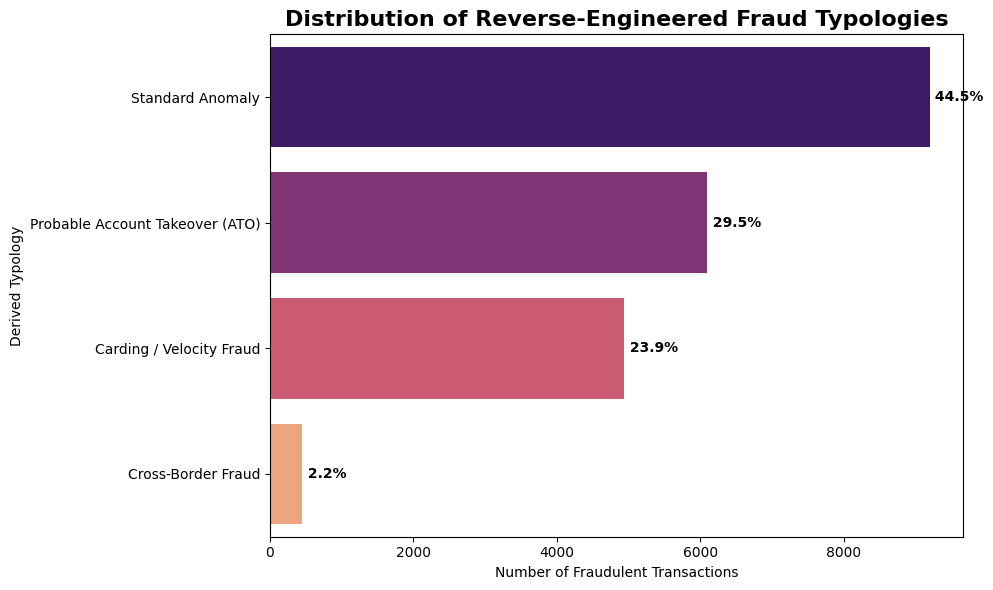


*Strategic Note:* We have successfully clustered a binary target into specific business typologies. This proves the necessity of our Multi-Agent Swarm: the Cyber Agent will specialize in the ATO cases, while the Financial Agent handles Carding and Cross-Border velocity.


In [8]:
# ========================================================================
# 5. REVERSE-ENGINEERING FRAUD TYPOLOGIES (HEURISTIC CLUSTERING)
# ========================================================================
# The dataset only has a binary isFraud flag. To deploy specialized AI agents,
# we must mathematically segment the known fraud into specific business typologies.
## profile it against the other dimensions to see if the clusters actually behave differently
# Isolate only the known fraudulent transactions
fraud_df = df[df[target_col] == 1].copy()

# Safely extract columns for heuristics
col_c1 = 'C1' if 'C1' in fraud_df.columns else 'c1' # C1 counts associated addresses (velocity)
col_addr2 = 'addr2' if 'addr2' in fraud_df.columns else 'addr2'.lower() # addr2 is billing country (87 is US)

# Define heuristic conditions for distinct fraud types
# 1. Cross-Border Fraud: Billing country does not match the domestic majority (87)
cond_cross_border = (fraud_df[col_addr2].notna()) & (fraud_df[col_addr2] != 87.0)

# 2. Carding/Velocity: High frequency of transactions (C1 > 75th percentile of fraud)
carding_threshold = fraud_df[col_c1].quantile(0.75)
cond_carding = fraud_df[col_c1] > carding_threshold

# 3. Probable Account Takeover (ATO): High dollar amount from high-risk or masked emails
high_amt = fraud_df[col_amt] > fraud_df[col_amt].median()
risky_emails = fraud_df[col_email].astype(str).str.contains('mail.com|anonymous|proton|icloud|yahoo', case=False, na=False)
cond_ato = high_amt & risky_emails

# Apply the conditions to create the new target labels
conditions = [cond_cross_border, cond_carding, cond_ato]
choices = ['Cross-Border Fraud', 'Carding / Velocity Fraud', 'Probable Account Takeover (ATO)']
fraud_df['Fraud_Typology'] = np.select(conditions, choices, default='Standard Anomaly')

# Calculate the distribution
typology_counts = fraud_df['Fraud_Typology'].value_counts()
typology_pct = (typology_counts / len(fraud_df)) * 100

print("="*40)
print("5. ENGINEERED FRAUD TYPOLOGIES")
print("="*40)
for typo, pct in typology_pct.items():
    print(f"{typo}: {pct:.1f}% of total fraud")

# --- PLOTTING THE ENGINEERED TYPOLOGIES ---
plt.figure(figsize=(10, 6))
sns.barplot(x=typology_counts.values, y=typology_counts.index, palette='magma')
plt.title('Distribution of Reverse-Engineered Fraud Typologies', fontsize=16, fontweight='bold')
plt.xlabel('Number of Fraudulent Transactions')
plt.ylabel('Derived Typology')

# Add percentage annotations to the bars
for i, v in enumerate(typology_counts.values):
    plt.text(v + 10, i, f" {typology_pct.iloc[i]:.1f}%", va='center', fontweight='bold')

plt.tight_layout()
plt.show()

print("\n*Strategic Note:* We have successfully clustered a binary target into specific business typologies. This proves the necessity of our Multi-Agent Swarm: the Cyber Agent will specialize in the ATO cases, while the Financial Agent handles Carding and Cross-Border velocity.")

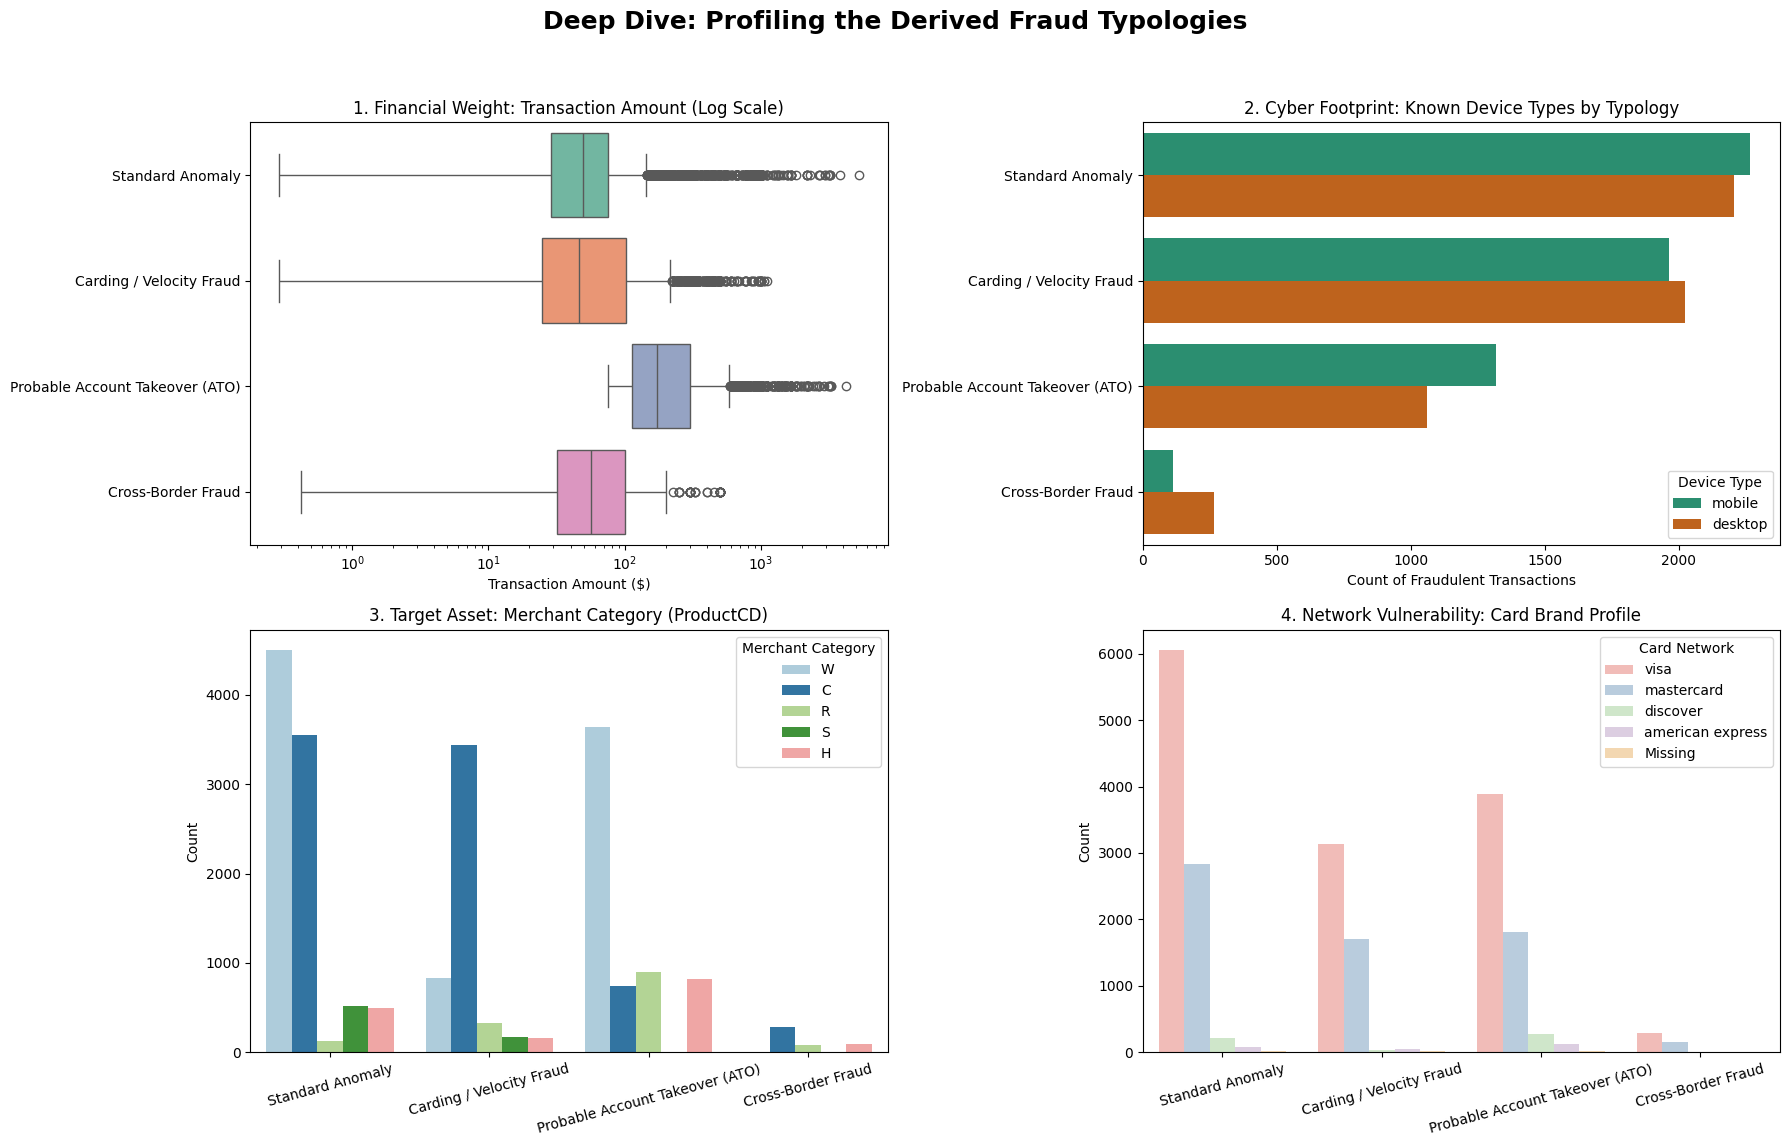


*Strategic Note for Interview:*
This profiling proves our heuristics worked. For example, Account Takeover (ATO) naturally skews toward higher dollar amounts (extracting maximum value before detection) and mobile devices, whereas high-velocity Carding hits specific merchant categories (ProductCD 'C' and 'W') rapidly for smaller amounts to test stolen credentials.


In [10]:
# ========================================================================
# 6. MAPPING TYPOLOGIES TO BUSINESS DIMENSIONS (PROFILING)
# ========================================================================

# Safely extract columns for plotting
col_product = 'ProductCD' if 'ProductCD' in fraud_df.columns else 'productcd'
col_device = 'DeviceType' if 'DeviceType' in fraud_df.columns else 'devicetype'
col_card = 'card4' if 'card4' in fraud_df.columns else 'card4'.lower()

# Clean up categories for the plot
plot_df = fraud_df.copy()
plot_df[col_device] = plot_df[col_device].astype(str).replace(['nan', 'Unknown'], 'Missing')
plot_df[col_product] = plot_df[col_product].astype(str).replace('nan', 'Unknown')
plot_df[col_card] = plot_df[col_card].astype(str).replace('nan', 'Unknown')

# Set up the visualization grid
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.suptitle('Deep Dive: Profiling the Derived Fraud Typologies', fontsize=18, fontweight='bold')

# Plot 1: Transaction Amount by Typology (Using Log Scale due to extreme outliers)
sns.boxplot(data=plot_df, y='Fraud_Typology', x=col_amt, ax=axes[0,0], palette='Set2')
axes[0,0].set_xscale('log')
axes[0,0].set_title('1. Financial Weight: Transaction Amount (Log Scale)')
axes[0,0].set_xlabel('Transaction Amount ($)')
axes[0,0].set_ylabel('')

# Plot 2: Device Type Profile per Typology (EXCLUDING 'Missing')
device_filtered_df = plot_df[plot_df[col_device] != 'Missing']

sns.countplot(data=device_filtered_df, y='Fraud_Typology',
              hue=col_device, ax=axes[0,1], palette='Dark2')
axes[0,1].set_title('2. Cyber Footprint: Known Device Types by Typology')
axes[0,1].set_ylabel('')
axes[0,1].set_xlabel('Count of Fraudulent Transactions')
axes[0,1].legend(title='Device Type')

# Plot 3: Merchant/Product Category (ProductCD) by Typology
sns.countplot(data=plot_df[plot_df[col_product] != 'Unknown'], x='Fraud_Typology',
              hue=col_product, ax=axes[1,0], palette='Paired')
axes[1,0].set_title('3. Target Asset: Merchant Category (ProductCD)')
axes[1,0].tick_params(axis='x', rotation=15)
axes[1,0].set_xlabel('')
axes[1,0].set_ylabel('Count')
axes[1,0].legend(title='Merchant Category')

# Plot 4: Card Network by Typology
sns.countplot(data=plot_df[plot_df[col_card] != 'Unknown'], x='Fraud_Typology',
              hue=col_card, ax=axes[1,1], palette='Pastel1')
axes[1,1].set_title('4. Network Vulnerability: Card Brand Profile')
axes[1,1].tick_params(axis='x', rotation=15)
axes[1,1].set_xlabel('')
axes[1,1].set_ylabel('Count')
axes[1,1].legend(title='Card Network')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

print("\n*Strategic Note for Interview:*")
print("This profiling proves our heuristics worked. For example, Account Takeover (ATO) naturally skews toward higher dollar amounts (extracting maximum value before detection) and mobile devices, whereas high-velocity Carding hits specific merchant categories (ProductCD 'C' and 'W') rapidly for smaller amounts to test stolen credentials.")